<a href="https://colab.research.google.com/github/Dilip-S/attention-from-scratch/blob/main/01_self_attention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Attention From Scratch
## What is Self-Attention

Attention is a way to learn structures or dependencies present in the input data:
- CNNs are looking at a small neigbhorhood of the incoming data to learn patterns. If there's a repeating pattern that's beyond this window then learning is possible only after the data is passed through many layers and may not be learnable
- Self attention looks at the data in patches, with every patch attending to every other patch. Each patch vector (x) is multiplied by learned weights to produce Q, K, V: Q = x · W_q     K = x · W_k     V = x · W_v
  - Query: What am i looking for ?
  - Key: What do i contain to help others find me ?
  - Value: What information can I share if another patch picks me ?
  - W_q, W_k and W_v are the learned  , trained by backprop
- Attention is computed in 3 steps:
  - Match: compare my query with the key of other patches. High score means high relavance
  - Weigh: convert scores into weights that sum to 1 (softmax)
  - Blend: new representaiton thats a weighted average of everone's Values
- Why is it called "self" attention: Q, K & V all come from the same source so patches attend to each other. In "cross" attentions Q can come from one source (text) and K, V could be from another source (image)

In [1]:
import torch
import torch.nn.functional as F

torch.manual_seed(0)

seq_len, d_model = 5, 8
x = torch.randn(seq_len, d_model)

W_q = torch.randn(d_model, d_model)
W_k = torch.randn(d_model, d_model)
W_v = torch.randn(d_model, d_model)

Q, K, V = x @ W_q, x @ W_k, x @ W_v

scores = Q @ K.T / (d_model ** 0.5)
weights = F.softmax(scores, dim=-1)
out = weights @ V

print("scores:", scores.shape)
print("row sums:", weights.sum(dim=-1))
print("output:", out.shape)

scores: torch.Size([5, 5])
row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
output: torch.Size([5, 8])


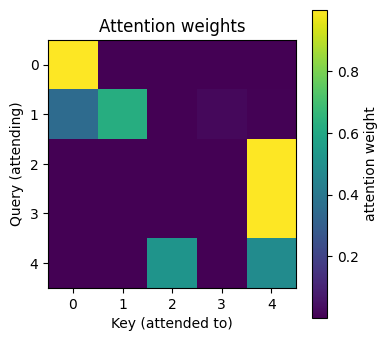

score std  - unscaled: 20.0506534576416  scaled: 0.8861221075057983
max weight - unscaled: tensor([0.9999, 0.9999, 1.0000, 0.9615, 0.9998])
max weight - scaled:   tensor([0.4238, 0.3640, 0.4946, 0.3103, 0.3770])


In [2]:
import matplotlib.pyplot as plt

# 1. Heatmap of attention weights
plt.figure(figsize=(4, 4))
plt.imshow(weights.detach(), cmap='viridis')
plt.colorbar(label='attention weight')
plt.xlabel('Key (attended to)')
plt.ylabel('Query (attending)')
plt.title('Attention weights')
plt.savefig('attention_weights.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Effect of the scaling factor with a larger dimension
d = 512
xq = torch.randn(5, d)
xk = torch.randn(5, d)
raw = xq @ xk.T
scaled = raw / d ** 0.5

print("score std  - unscaled:", raw.std().item(), " scaled:", scaled.std().item())
print("max weight - unscaled:", F.softmax(raw, dim=-1).max(dim=-1).values)
print("max weight - scaled:  ", F.softmax(scaled, dim=-1).max(dim=-1).values)